# Multi-Agent System with LangGraph

## Setup

In [28]:
%pip install -q langgraph langchain langchain-core langchain-groq wikipedia-api pydantic

In [29]:
import os
import operator
import getpass
from typing import Annotated, TypedDict

import wikipediaapi
from pydantic import BaseModel, Field
from IPython.display import Image, display

from langchain_groq import ChatGroq
from langchain_core.tools import tool
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

In [30]:
os.environ["GROQ_API_KEY"] = "...."
MODEL = "openai/gpt-oss-120b"
llm = ChatGroq(model=MODEL, temperature=0, max_retries=6)

In [31]:
def print_state(state, max_chars=700):
    for key, value in state.items():
        if key == "messages":
            print("messages:")
            for m in value:
                text = str(m.content)[:200].replace("\n", " ")
                calls = f" tool_calls={m.tool_calls}" if getattr(m, "tool_calls", None) else ""
                print(f"  - {type(m).__name__}: {text}{calls}")
        elif isinstance(value, str) and len(value) > max_chars:
            print(f"{key} (len={len(value)}): {value[:max_chars]} ...")
        else:
            print(f"{key}: {value!r}")


def show_graph(app):
    g = app.get_graph()
    try:
        display(Image(g.draw_mermaid_png()))
    except Exception as e:
        print(g.draw_mermaid())

## Part 1: Build the Researcher Graph

### Task 1: Define ResearcherState

In [32]:
class ResearcherState(TypedDict):
    task: str
    research: str
    messages: Annotated[list, add_messages]
    trace: Annotated[list, operator.add]

### Task 2: Define the Wikipedia Search Tool

**Handling large pages:** limit the number of pages returned and truncate each page's text to a fixed number of characters, keeping the page title with it, so the output always fits in the LLM context.

In [33]:
wiki = wikipediaapi.Wikipedia(user_agent="langgraph-assignment/1.0 (student@example.com)")

MAX_PAGES = 3
MAX_CHARS_PER_PAGE = 1500


@tool
def wikipedia_search(query: str) -> str:
    """Search Wikipedia for the query and return the raw text of the top matching pages."""
    try:
        results = wiki.search(query, limit=MAX_PAGES)
    except Exception as e:
        return f"Wikipedia search failed: {e}"
    chunks = []
    for title, page in results.pages.items():
        chunks.append(f"# {title}\n{page.text[:MAX_CHARS_PER_PAGE]}")
    if not chunks:
        return "No Wikipedia results found."
    return "\n\n".join(chunks)

### Task 3: Implement researcher_node

In [34]:
RESEARCHER_SYSTEM_PROMPT = (
    "You are a research assistant. Gather RAW information about the user's task using the "
    "wikipedia_search tool. Call the tool first. Do NOT summarize. Do NOT rewrite or format. "
    "Do NOT add commentary. Output must be raw notes only, copied exactly as the tool returned them."
)

researcher_llm = llm.bind_tools([wikipedia_search])


def researcher_node(state: ResearcherState) -> dict:
    prompt = [
        SystemMessage(content=RESEARCHER_SYSTEM_PROMPT),
        HumanMessage(content=state["task"]),
    ] + state["messages"]

    response = researcher_llm.invoke(prompt)

    tool_outputs = [m.content for m in state["messages"] if isinstance(m, ToolMessage)]
    research = "\n\n".join(tool_outputs)
    if not research and not response.tool_calls:
        research = response.content

    return {
        "research": research,
        "messages": [response],
        "trace": ["researcher"],
    }

### Task 4: Build and Compile the Researcher Graph

In [35]:
research_tools = ToolNode([wikipedia_search])

researcher_builder = StateGraph(ResearcherState)
researcher_builder.add_node("researcher", researcher_node)
researcher_builder.add_node("research_tools", research_tools)
researcher_builder.add_edge(START, "researcher")
researcher_builder.add_conditional_edges(
    "researcher", tools_condition, {"tools": "research_tools", END: END}
)
researcher_builder.add_edge("research_tools", "researcher")

researcher_app = researcher_builder.compile()

### Task 5: Run the Researcher Standalone

In [36]:
researcher_result = researcher_app.invoke({
    "task": "Research the Python programming language: its history, creator and main features.",
    "research": "",
    "messages": [],
    "trace": [],
})

print_state(researcher_result)
print()
print("research non-empty:", bool(researcher_result["research"].strip()))
print("trace contains 'researcher':", "researcher" in researcher_result["trace"])

task: 'Research the Python programming language: its history, creator and main features.'
research (len=4611): # Python (programming language)
Python is a high-level, general-purpose programming language that emphasizes code readability, simplicity, and ease-of-writing with the use of significant indentation, an extensive ("batteries-included") standard library, and garbage collection. Python supports multiple programming paradigms but with an emphasis on object-oriented programming and dynamic typing.
Guido van Rossum began working on Python in the late 1980s as a successor to the ABC programming language. Python 3.0, released in 2008, was a major revision and not completely backward-compatible with earlier versions. Beginning with Python 3.5, capabilities and keywords for typing were added to the l ...
messages:
  - AIMessage:  tool_calls=[{'name': 'wikipedia_search', 'args': {'query': 'Python programming language'}, 'id': 'fc_85e4d34e-7ab4-4b0c-beee-e33032a29fb1', 'type': 'tool_call

### Task 6: Visualize the Researcher Graph

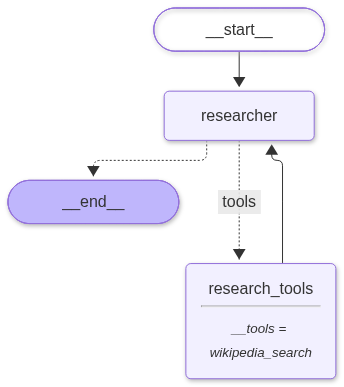

In [37]:
show_graph(researcher_app)

## Part 2: Build the Writer Graph

### Task 1: Define WriterState

In [38]:
class WriterState(TypedDict):
    task: str
    research: str
    feedback: str
    draft: str
    attempts: int
    messages: Annotated[list, add_messages]
    trace: Annotated[list, operator.add]

### Task 2: Implement writer_node

In [39]:
writer_llm = ChatGroq(model=MODEL, temperature=0.7, max_retries=6)

WRITER_SYSTEM_PROMPT = (
    "You are a professional writer. Follow every constraint in the task exactly. "
    "Return ONLY the text of the draft, with no explanations."
)


def writer_node(state: WriterState) -> dict:
    parts = [f"TASK:\n{state['task']}"]

    if state["research"]:
        parts.append(f"RAW SOURCE MATERIAL (use only if useful):\n{state['research']}")

    if state["feedback"]:
        if state["draft"]:
            parts.append(f"PREVIOUS DRAFT:\n{state['draft']}")
        parts.append(f"REVIEWER FEEDBACK (revise the draft to address it):\n{state['feedback']}")

    prompt = [
        SystemMessage(content=WRITER_SYSTEM_PROMPT),
        HumanMessage(content="\n\n".join(parts)),
    ]
    response = writer_llm.invoke(prompt)

    return {
        "draft": response.content,
        "attempts": state["attempts"] + 1,
        "messages": [response],
        "trace": ["writer"],
    }

### Task 3: Build and Compile the Writer Graph

In [40]:
writer_builder = StateGraph(WriterState)
writer_builder.add_node("writer", writer_node)
writer_builder.add_edge(START, "writer")
writer_builder.add_edge("writer", END)

writer_app = writer_builder.compile()

### Task 4: Run the Writer Standalone

In [41]:
writer_result = writer_app.invoke({
    "task": "Write a 3-sentence pitch for a plant-watering mobile app.",
    "research": "", "feedback": "", "draft": "", "attempts": 0,
    "messages": [], "trace": [],
})

print_state(writer_result)
print()
print("draft non-empty:", bool(writer_result["draft"].strip()))
print("attempts == 1:", writer_result["attempts"] == 1)
print("trace == ['writer']:", writer_result["trace"] == ["writer"])

task: 'Write a 3-sentence pitch for a plant-watering mobile app.'
research: ''
feedback: ''
draft: 'Never forget to water your green friends again—our app sends smart, timed reminders based on each plant’s species, sunlight needs, and local weather. With a simple photo scan, it creates a personalized watering schedule, tracks moisture levels, and alerts you when it’s time to hydrate or hold back. Stay confident, keep your garden thriving, and watch your indoor jungle flourish with just a tap.'
attempts: 1
messages:
  - AIMessage: Never forget to water your green friends again—our app sends smart, timed reminders based on each plant’s species, sunlight needs, and local weather. With a simple photo scan, it creates a personalize
trace: ['writer']

draft non-empty: True
attempts == 1: True
trace == ['writer']: True


### Task 5: Visualize the Writer Graph

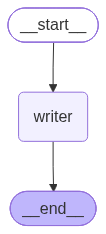

In [42]:
show_graph(writer_app)

## Part 3: Build the Reviewer Graph

### Task 1: Define ReviewerState

In [43]:
class ReviewerState(TypedDict):
    task: str
    draft: str
    feedback: str
    approved: bool
    messages: Annotated[list, add_messages]
    trace: Annotated[list, operator.add]

### Task 2: Define a Structured Output Model

In [44]:
class Review(BaseModel):
    feedback: str = Field(description="Specific, actionable feedback on the draft.")
    approved: bool = Field(description="True if the draft is good enough to publish.")

### Task 3: Implement reviewer_node

In [45]:
reviewer_llm = llm.with_structured_output(Review)

REVIEWER_SYSTEM_PROMPT = (
    "You are a strict, demanding editor. Review the draft against the task. "
    "Check every constraint in the task one by one (length, word count, format, tone, clarity, originality) "
    "and give specific, actionable feedback. Only set approved=True if the draft meets ALL constraints "
    "and you cannot name any concrete improvement. If you can still suggest a meaningful improvement, "
    "set approved=False."
)


def reviewer_node(state: ReviewerState) -> dict:
    prompt = [
        SystemMessage(content=REVIEWER_SYSTEM_PROMPT),
        HumanMessage(content=f"TASK:\n{state['task']}\n\nDRAFT:\n{state['draft']}"),
    ]
    review = reviewer_llm.invoke(prompt)

    return {
        "feedback": review.feedback,
        "approved": review.approved,
        "messages": [AIMessage(content=review.feedback)],
        "trace": ["reviewer"],
    }

### Task 4: Build and Compile the Reviewer Graph

In [46]:
reviewer_builder = StateGraph(ReviewerState)
reviewer_builder.add_node("reviewer", reviewer_node)
reviewer_builder.add_edge(START, "reviewer")
reviewer_builder.add_edge("reviewer", END)

reviewer_app = reviewer_builder.compile()

### Task 5: Run the Reviewer Standalone

In [47]:
reviewer_result = reviewer_app.invoke({
    "task": "Write a slogan for a coffee shop.",
    "draft": "Coffee that wakes you up and keeps you going.",
    "feedback": "", "approved": False, "messages": [], "trace": [],
})

print_state(reviewer_result)
print()
print("feedback non-empty:", bool(reviewer_result["feedback"].strip()))
print("approved is bool:", isinstance(reviewer_result["approved"], bool))
print("trace == ['reviewer']:", reviewer_result["trace"] == ["reviewer"])

task: 'Write a slogan for a coffee shop.'
draft: 'Coffee that wakes you up and keeps you going.'
feedback (len=1064): 1. **Length/Word Count**: A slogan should be punchy and easy to remember, typically 5‑7 words. Your draft is 11 words, which is too long for a tagline.
2. **Brevity & Impact**: The phrase "keeps you going" is vague and dilutes the immediate impact. Aim for a tighter, more vivid statement.
3. **Originality**: "Coffee that wakes you up" is a common trope; it lacks a unique hook that differentiates the shop.
4. **Tone**: While friendly, the tone could be more energetic or playful to match a coffee shop’s vibe.
5. **Clarity & Memorability**: Slogans benefit from rhythm or alliteration. Your draft reads like a description rather than a memorable catch‑phrase.

**Actionable suggestions**:
- Reduce ...
approved: False
messages:
  - AIMessage: 1. **Length/Word Count**: A slogan should be punchy and easy to remember, typically 5‑7 words. Your draft is 11 words, which is too long

### Task 6: Visualize the Reviewer Graph

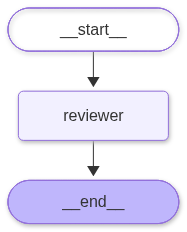

In [48]:
show_graph(reviewer_app)

## Part 4: Build the Orchestration Layer

### Task 1: Define OrchestratorState

In [49]:
class OrchestratorState(TypedDict):
    task: str
    research: str
    draft: str
    feedback: str
    approved: bool
    attempts: int
    trace: Annotated[list, operator.add]

### Task 2: Wrap Each Compiled Graph as a Node

In [50]:
def run_researcher(state: OrchestratorState) -> dict:
    out = researcher_app.invoke({
        "task": state["task"],
        "research": "",
        "messages": [],
        "trace": [],
    })
    return {
        "research": out["research"],
        "trace": ["researcher"],
    }


def run_writer(state: OrchestratorState) -> dict:
    out = writer_app.invoke({
        "task": state["task"],
        "research": state["research"],
        "feedback": state["feedback"],
        "draft": state["draft"],
        "attempts": state["attempts"],
        "messages": [],
        "trace": [],
    })
    return {
        "draft": out["draft"],
        "attempts": out["attempts"],
        "trace": out["trace"],
    }


def run_reviewer(state: OrchestratorState) -> dict:
    out = reviewer_app.invoke({
        "task": state["task"],
        "draft": state["draft"],
        "feedback": "",
        "approved": False,
        "messages": [],
        "trace": [],
    })
    return {
        "feedback": out["feedback"],
        "approved": out["approved"],
        "trace": out["trace"],
    }

### Task 3: Define the Router

In [51]:
MAX_ATTEMPTS = 5


def route_after_review(state: OrchestratorState) -> str:
    if state["approved"]:
        return "end"
    if state["attempts"] >= MAX_ATTEMPTS:
        return "end"
    return "writer"

### Task 4: Assemble & Visualize the Orchestration Graph

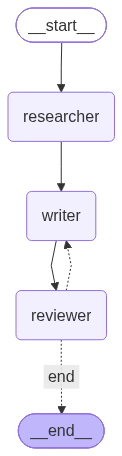

In [52]:
orch_builder = StateGraph(OrchestratorState)
orch_builder.add_node("researcher", run_researcher)
orch_builder.add_node("writer", run_writer)
orch_builder.add_node("reviewer", run_reviewer)

orch_builder.add_edge(START, "researcher")
orch_builder.add_edge("researcher", "writer")
orch_builder.add_edge("writer", "reviewer")
orch_builder.add_conditional_edges(
    "reviewer", route_after_review, {"writer": "writer", "end": END}
)

multi_agent_app = orch_builder.compile()
show_graph(multi_agent_app)

### Task 5: Run the Orchestrated Workflow

In [53]:
final_state = multi_agent_app.invoke({
    "task": "Write a single-sentence slogan for a coffee shop. Keep it under 10 words.",
    "research": "", "draft": "", "feedback": "", "approved": False,
    "attempts": 0, "trace": [],
})

print_state(final_state)

task: 'Write a single-sentence slogan for a coffee shop. Keep it under 10 words.'
research (len=22441): # Pocket Coffee
Pocket Coffee is a brand of the Ferrero company for a chocolate confectionery, sold internationally. First marketed in Italy in 1968, each Pocket Coffee is an individually wrapped shell of dark chocolate containing liquid espresso. As with Ferrero's Rocher, Mon Chéri, and Raffaello, production limits sales from November to April.
William Salice, assistant to Ferrero's owner, Michele Ferrero, conceived the product in the early 1960s after noticing no bars at Italy's then relatively new Autogrills, a proprietary eponym synonymous with Italian highway rest stops. Ferrero conceived a product for anyone working long hours, e.g., truck drivers. Michele Ferrero conceived the slogan: ...
draft: 'Sip brilliance, fuel your day.'
feedback: "The draft meets all requirements: it's a single sentence, contains only 5 words (under the 10-word limit), and functions as a clear, catchy 

In [54]:
trace = final_state["trace"]
expected = ["researcher"] + ["writer", "reviewer"] * final_state["attempts"]

print("research populated:", bool(final_state["research"].strip()))
print("draft populated:", bool(final_state["draft"].strip()))
print("attempts > 1:", final_state["attempts"] > 1, "| attempts =", final_state["attempts"])
print("trace:", trace)
print("trace order correct:", trace == expected)
print("approved == True:", final_state["approved"] is True)

research populated: True
draft populated: True
attempts > 1: False | attempts = 1
trace: ['researcher', 'writer', 'reviewer']
trace order correct: True
approved == True: True
